# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task A2: Concrete Compressive Strength Prediction (Non-linear Physical Modeling)
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup & Inline Plotting
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("A2 Regression environment initialized with inline plotting!")


A2 Regression environment initialized with inline plotting!


In [2]:
# 2. Dataset Loading & Descriptive Statistics
df = pd.read_csv("data/concrete_data.csv")
print(f"Dataset Shape: {df.shape[0]} samples x {df.shape[1]} columns")
print("\nDescriptive Statistics (Yeh 1998 Benchmark):")
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))


Dataset Shape: 1030 samples x 9 columns


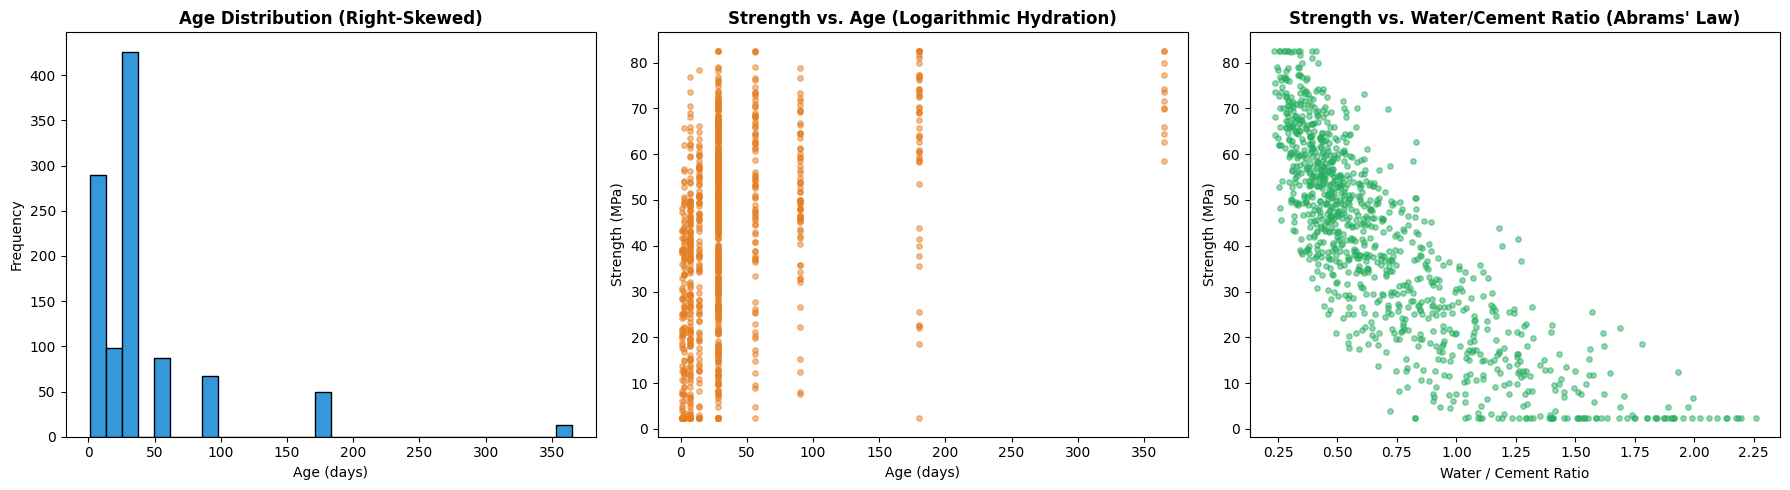

In [3]:
# 3. Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age Distribution
axes[0].hist(df['age'], bins=30, color='#3498db', edgecolor='black')
axes[0].set_title("Age Distribution (Right-Skewed)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Age (days)")
axes[0].set_ylabel("Frequency")

# Strength vs Age (Non-linear Log Rise)
axes[1].scatter(df['age'], df['compressive_strength'], alpha=0.5, color='#e67e22', s=15)
axes[1].set_title("Strength vs. Age (Logarithmic Hydration)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Age (days)")
axes[1].set_ylabel("Strength (MPa)")

# Strength vs Water/Cement Ratio (Abrams' Law)
axes[2].scatter(df['water']/df['cement'], df['compressive_strength'], alpha=0.5, color='#27ae60', s=15)
axes[2].set_title("Strength vs. Water/Cement Ratio (Abrams' Law)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Water / Cement Ratio")
axes[2].set_ylabel("Strength (MPa)")

plt.tight_layout()
plt.show()


In [4]:
# 4. Domain Feature Engineering (Abrams' Law & Log Age) & Disjoint Split
df['water_cement_ratio'] = df['water'] / df['cement']
df['log_age'] = np.log(df['age'] + 1)

features_raw = ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']
features_eng = features_raw + ['water_cement_ratio', 'log_age']

X_raw = df[features_raw]
X_eng = df[features_eng]
y = df['compressive_strength']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y, test_size=0.20, random_state=RANDOM_SEED)
X_train_eng, X_test_eng = X_eng.loc[X_train_raw.index], X_eng.loc[X_test_raw.index]

print(f"Train samples: {X_train_eng.shape[0]} | Test samples: {X_test_eng.shape[0]}")
print(f"Engineered features added: water_cement_ratio, log_age")


Train samples: 824 | Test samples: 206
Engineered features added: water_cement_ratio, log_age


In [5]:
# 5. Model Training & Feature Engineering Impact (Raw vs Engineered)
models_config = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Polynomial + Ridge": Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge(alpha=10.0, random_state=RANDOM_SEED))
    ]),
    "Random Forest Regressor": Pipeline([
        ('scaler', StandardScaler()),
        ('rf', RandomForestRegressor(n_estimators=100, max_depth=12, random_state=RANDOM_SEED))
    ]),
    "MLP Regressor": Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=RANDOM_SEED))
    ])
}

res_models = {}
print(f"{'Model':<30} | Raw RMSE | Eng RMSE | Eng R2  | Eng MAE")
print("-" * 75)
for name, m in models_config.items():
    m.fit(X_train_raw, y_train)
    pred_raw = m.predict(X_test_raw)
    rmse_raw = float(np.sqrt(mean_squared_error(y_test, pred_raw)))

    m.fit(X_train_eng, y_train)
    pred_eng = m.predict(X_test_eng)
    rmse_eng = float(np.sqrt(mean_squared_error(y_test, pred_eng)))
    r2_eng = float(r2_score(y_test, pred_eng))
    mae_eng = float(mean_absolute_error(y_test, pred_eng))
    res_models[name] = {"rmse_raw": rmse_raw, "rmse_eng": rmse_eng, "r2_eng": r2_eng, "mae_eng": mae_eng, "pred_eng": pred_eng}
    print(f"{name:<30} | {rmse_raw:<8.2f} | {rmse_eng:<8.2f} | {r2_eng:<7.4f} | {mae_eng:.2f}")


Model                          | Raw RMSE | Eng RMSE | Eng R2  | Eng MAE
----------------------------------------------------------------------
Linear Regression (Baseline)   | 7.73     | 4.05     | 0.9591  | 3.23
Polynomial + Ridge             | 6.08     | 3.61     | 0.9676  | 2.88
Random Forest Regressor        | 5.51     | 4.82     | 0.9422  | 3.66
MLP Regressor                  | 4.69     | 3.50     | 0.9696  | 2.70


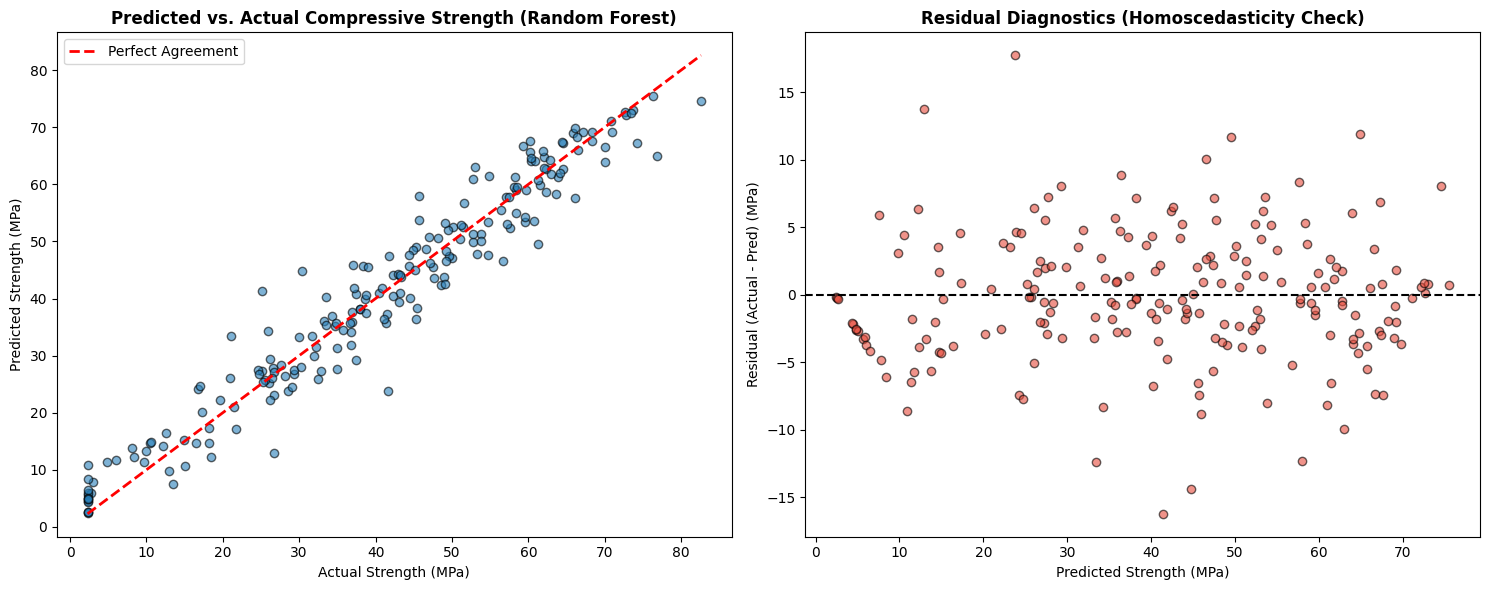

In [6]:
# 6. Diagnostic Visualizations: Predicted vs Actual & Residual Error Analysis
y_pred_rf = res_models["Random Forest Regressor"]["pred_eng"]
residuals = y_test.values - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Predicted vs Actual
axes[0].scatter(y_test, y_pred_rf, alpha=0.6, color='#2980b9', edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Perfect Agreement")
axes[0].set_title("Predicted vs. Actual Compressive Strength (Random Forest)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Actual Strength (MPa)")
axes[0].set_ylabel("Predicted Strength (MPa)")
axes[0].legend()

# Residual Plot
axes[1].scatter(y_pred_rf, residuals, alpha=0.6, color='#e74c3c', edgecolors='k')
axes[1].axhline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title("Residual Diagnostics (Homoscedasticity Check)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Predicted Strength (MPa)")
axes[1].set_ylabel("Residual (Actual - Pred) (MPa)")

plt.tight_layout()
plt.show()


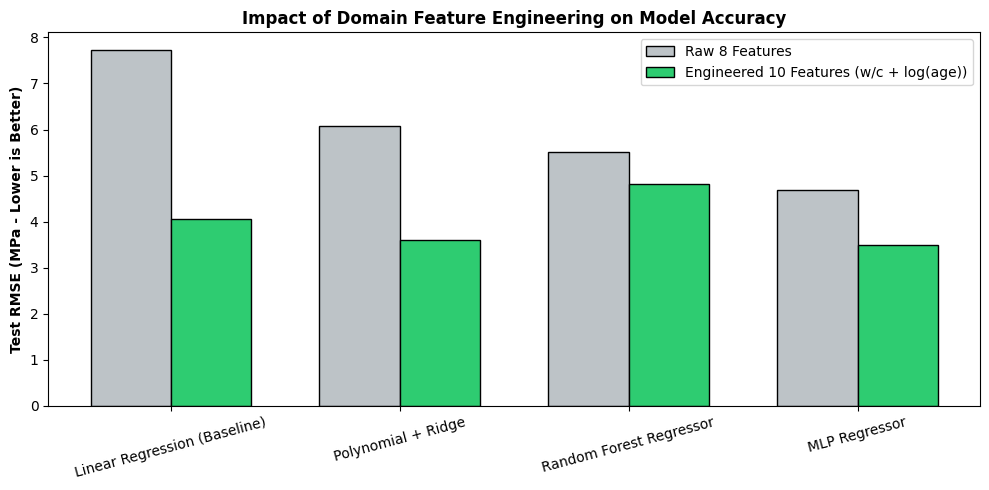

In [7]:
# 7. Impact of Feature Engineering: Bar Chart Comparison Across Architectures
fig, ax = plt.subplots(figsize=(10, 5))
names = list(res_models.keys())
rmse_raw_list = [res_models[m]["rmse_raw"] for m in names]
rmse_eng_list = [res_models[m]["rmse_eng"] for m in names]
x_pos = np.arange(len(names))
width = 0.35

ax.bar(x_pos - width/2, rmse_raw_list, width, label='Raw 8 Features', color='#bdc3c7', edgecolor='k')
ax.bar(x_pos + width/2, rmse_eng_list, width, label='Engineered 10 Features (w/c + log(age))', color='#2ecc71', edgecolor='k')
ax.set_ylabel('Test RMSE (MPa - Lower is Better)', fontweight='bold')
ax.set_title('Impact of Domain Feature Engineering on Model Accuracy', fontsize=12, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(names, rotation=15)
ax.legend()

plt.tight_layout()
plt.show()
